In [2]:
import pandas as pd

file_path = '/content/online_retail_II.xlsx'

df = pd.read_excel(file_path)

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [ ]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (525461, 8)

Columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [ ]:
df.info()

print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Duplicate Rows ---")
print("Duplicates:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB

--- Missing Values ---
Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

--- Duplicate Rows ---
Duplicates: 6865


In [ ]:

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (518596, 8)


In [ ]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print(df["InvoiceDate"].dtype)
print(df["InvoiceDate"].head())

datetime64[ns]
0   2009-12-01 07:45:00
1   2009-12-01 07:45:00
2   2009-12-01 07:45:00
3   2009-12-01 07:45:00
4   2009-12-01 07:45:00
Name: InvoiceDate, dtype: datetime64[ns]


In [ ]:
print(df.columns.tolist())


['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


In [ ]:
df["IsCancelled"] = df["Invoice"].astype(str).str.startswith("C")

df = df[df["IsCancelled"] == False].copy()

print("Shape after removing cancellations:", df.shape)

Shape after removing cancellations: (508414, 9)


In [ ]:
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)].copy()

print("Shape after removing invalid transactions:", df.shape)
print("Minimum Quantity:", df["Quantity"].min())
print("Minimum Price:", df["Price"].min())

Shape after removing invalid transactions: (504730, 9)
Minimum Quantity: 1
Minimum Price: 0.001


In [ ]:
df["Revenue"] = df["Quantity"] * df["Price"]

print(df[["Quantity", "Price", "Revenue"]].head())

   Quantity  Price  Revenue
0        12   6.95     83.4
1        12   6.75     81.0
2        12   6.75     81.0
3        48   2.10    100.8
4        24   1.25     30.0


In [ ]:
print("Missing Customer IDs before:", df["Customer ID"].isnull().sum())

df = df.dropna(subset=["Customer ID"]).copy()

print("Missing Customer IDs after:", df["Customer ID"].isnull().sum())
print("Shape after removing missing Customer IDs:", df.shape)

Missing Customer IDs before: 103814
Missing Customer IDs after: 0
Shape after removing missing Customer IDs: (400916, 10)


In [ ]:
df["Year"] = df["InvoiceDate"].dt.year
df["Month"] = df["InvoiceDate"].dt.month
df["Quarter"] = df["InvoiceDate"].dt.quarter

print(df[["InvoiceDate", "Year", "Month", "Quarter"]].head())

          InvoiceDate  Year  Month  Quarter
0 2009-12-01 07:45:00  2009     12        4
1 2009-12-01 07:45:00  2009     12        4
2 2009-12-01 07:45:00  2009     12        4
3 2009-12-01 07:45:00  2009     12        4
4 2009-12-01 07:45:00  2009     12        4


In [ ]:
df["MonthYear"] = df["InvoiceDate"].dt.to_period("M").astype(str)

print(df[["InvoiceDate", "MonthYear"]].head())


          InvoiceDate MonthYear
0 2009-12-01 07:45:00   2009-12
1 2009-12-01 07:45:00   2009-12
2 2009-12-01 07:45:00   2009-12
3 2009-12-01 07:45:00   2009-12
4 2009-12-01 07:45:00   2009-12


In [ ]:
print("Final Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nFirst 5 Rows:")
display(df.head())

Final Shape: (400916, 14)

Columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'IsCancelled', 'Revenue', 'Year', 'Month', 'Quarter', 'MonthYear']

Missing Values:
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
IsCancelled    0
Revenue        0
Year           0
Month          0
Quarter        0
MonthYear      0
dtype: int64

First 5 Rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancelled,Revenue,Year,Month,Quarter,MonthYear
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,83.4,2009,12,4,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0,2009,12,4,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0,2009,12,4,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,100.8,2009,12,4,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,30.0,2009,12,4,2009-12


In [ ]:
import pandas as pd
import numpy as np


total_revenue = df["Revenue"].sum()

total_orders = df["Invoice"].nunique()


total_customers = df["Customer ID"].nunique()


total_products = df["StockCode"].nunique()

average_order_value = total_revenue / total_orders

kpi_results = pd.DataFrame({
    "Business KPI": [
        "Total Revenue",
        "Total Orders",
        "Total Customers",
        "Total Products",
        "Average Order Value"
    ],
    "Value": [
        f"£{total_revenue:,.2f}",
        f"{total_orders:,}",
        f"{total_customers:,}",
        f"{total_products:,}",
        f"£{average_order_value:,.2f}"
    ]
})

display(kpi_results)

,Business KPI,Value
0,Total Revenue,"£8,798,233.74"
1,Total Orders,"19,213"
2,Total Customers,"4,312"
3,Total Products,"4,017"
4,Average Order Value,£457.93


MONTHLY REVENUE


,MonthYear,Revenue
0,2009-12,683504.010
1,2010-01,555802.672
2,2010-02,504558.956
3,2010-03,696978.471
4,2010-04,591982.002
5,2010-05,597833.380
6,2010-06,636371.130
7,2010-07,589736.170
8,2010-08,602224.600
9,2010-09,829013.951


QUARTERLY REVENUE


,QuarterYear,Revenue
0,2009-Q4,683504.010
1,2010-Q1,1757340.099
2,2010-Q2,1826186.512
3,2010-Q3,2020974.721
4,2010-Q4,2510228.402


YEARLY REVENUE


,Year,Revenue
0,2009,683504.010
1,2010,8114729.734



BUSINESS HIGHLIGHTS
Highest Revenue Month: 2010-11
Revenue: £1,166,460.02
Highest Revenue Quarter: 2010-Q4
Revenue: £2,510,228.40


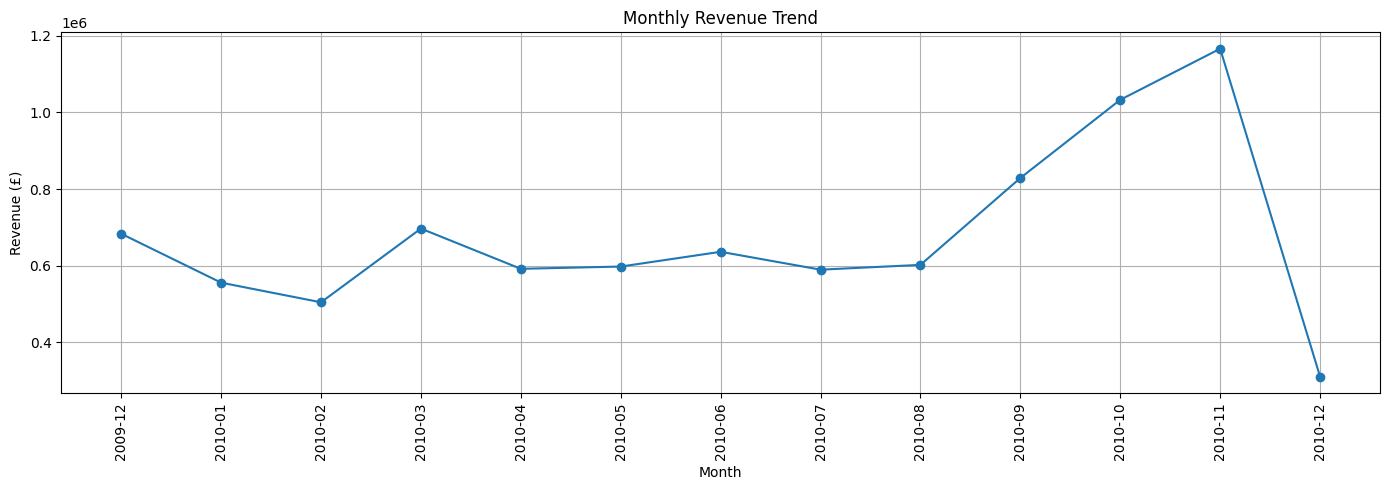

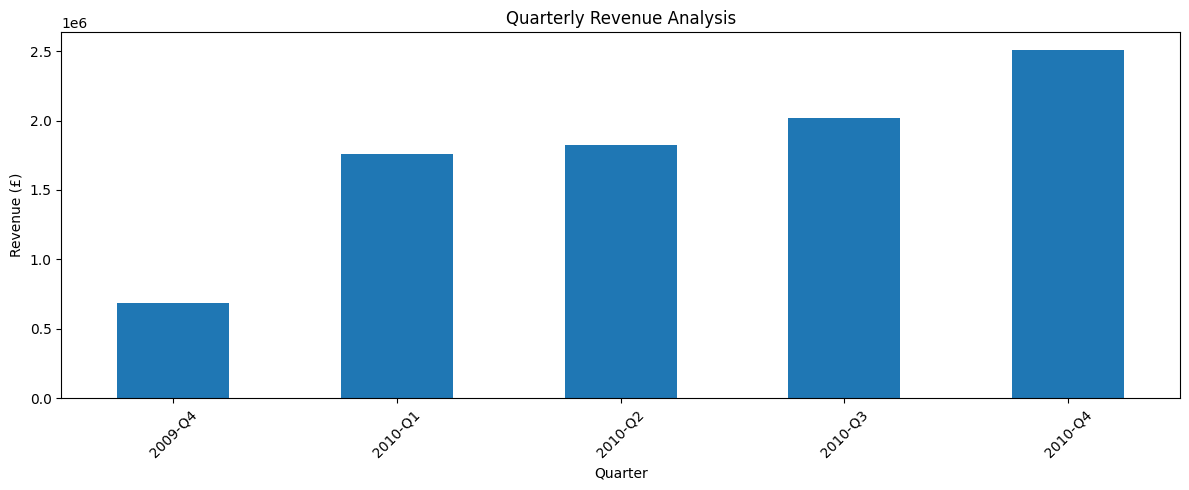

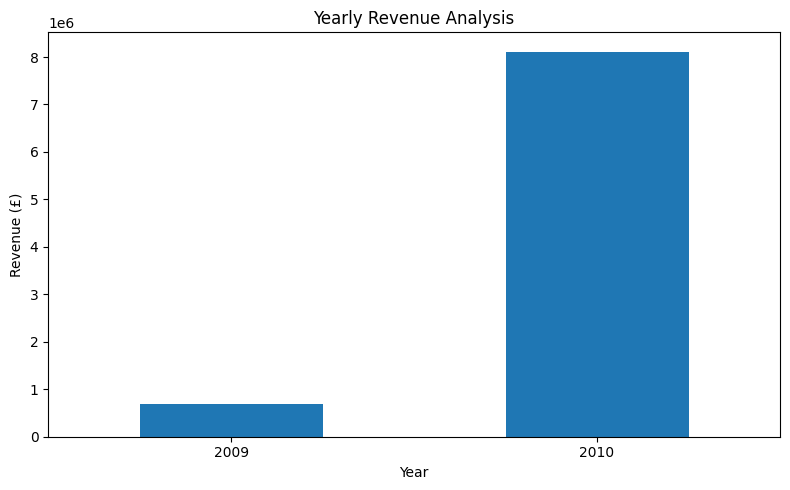

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_excel('/content/online_retail_II.xlsx')


df = df.drop_duplicates()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["IsCancelled"] = df["Invoice"].astype(str).str.startswith("C")

df = df[~df["IsCancelled"]].copy()
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)].copy()
df = df.dropna(subset=["Customer ID"]).copy()


df["Revenue"] = df["Quantity"] * df["Price"]


df["MonthYear"] = df["InvoiceDate"].dt.to_period("M")
df["QuarterYear"] = (
    df["InvoiceDate"].dt.year.astype(str)
    + "-Q"
    + df["InvoiceDate"].dt.quarter.astype(str)
)
df["Year"] = df["InvoiceDate"].dt.year


monthly_revenue = df.groupby("MonthYear")["Revenue"].sum()


quarterly_revenue = df.groupby("QuarterYear")["Revenue"].sum()


yearly_revenue = df.groupby("Year")["Revenue"].sum()


highest_month = monthly_revenue.idxmax()
highest_month_revenue = monthly_revenue.max()


highest_quarter = quarterly_revenue.idxmax()
highest_quarter_revenue = quarterly_revenue.max()


print("MONTHLY REVENUE")
display(monthly_revenue.reset_index())

print("QUARTERLY REVENUE")
display(quarterly_revenue.reset_index())

print("YEARLY REVENUE")
display(yearly_revenue.reset_index())

print("\nBUSINESS HIGHLIGHTS")
print(f"Highest Revenue Month: {highest_month}")
print(f"Revenue: £{highest_month_revenue:,.2f}")
print(f"Highest Revenue Quarter: {highest_quarter}")
print(f"Revenue: £{highest_quarter_revenue:,.2f}")


plt.figure(figsize=(14, 5))
plt.plot(monthly_revenue.index.astype(str),
         monthly_revenue.values, marker='o')
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
quarterly_revenue.plot(kind="bar")
plt.title("Quarterly Revenue Analysis")
plt.xlabel("Quarter")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))
yearly_revenue.plot(kind="bar")
plt.title("Yearly Revenue Analysis")
plt.xlabel("Year")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

COUNTRY-WISE BUSINESS PERFORMANCE


,Total_Revenue,Total_Orders,Total_Customers,Total_Quantity,Average_Order_Value
Country,,,,,
United Kingdom,7381644.43,17612,3969,4430148,419.13
EIRE,356041.86,316,5,181413,1126.71
Netherlands,268784.35,135,22,183615,1991.00
Germany,202025.39,347,67,108615,582.21
France,146107.07,236,47,162048,619.10
Sweden,53147.99,68,16,52417,781.59
Denmark,50906.85,26,9,229690,1957.96
Spain,47568.65,66,25,22841,720.74
Switzerland,43921.39,40,14,22255,1098.03



TOP 10 REVENUE-GENERATING COUNTRIES


,Total_Revenue,Total_Orders,Total_Customers,Total_Quantity,Average_Order_Value
Country,,,,,
United Kingdom,7381644.43,17612,3969,4430148,419.13
EIRE,356041.86,316,5,181413,1126.71
Netherlands,268784.35,135,22,183615,1991.00
Germany,202025.39,347,67,108615,582.21
France,146107.07,236,47,162048,619.10
Sweden,53147.99,68,16,52417,781.59
Denmark,50906.85,26,9,229690,1957.96
Spain,47568.65,66,25,22841,720.74
Switzerland,43921.39,40,14,22255,1098.03


/tmp/ipykernel_548/58094392.py:47: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  top_countries["Revenue_Percentage"] = (


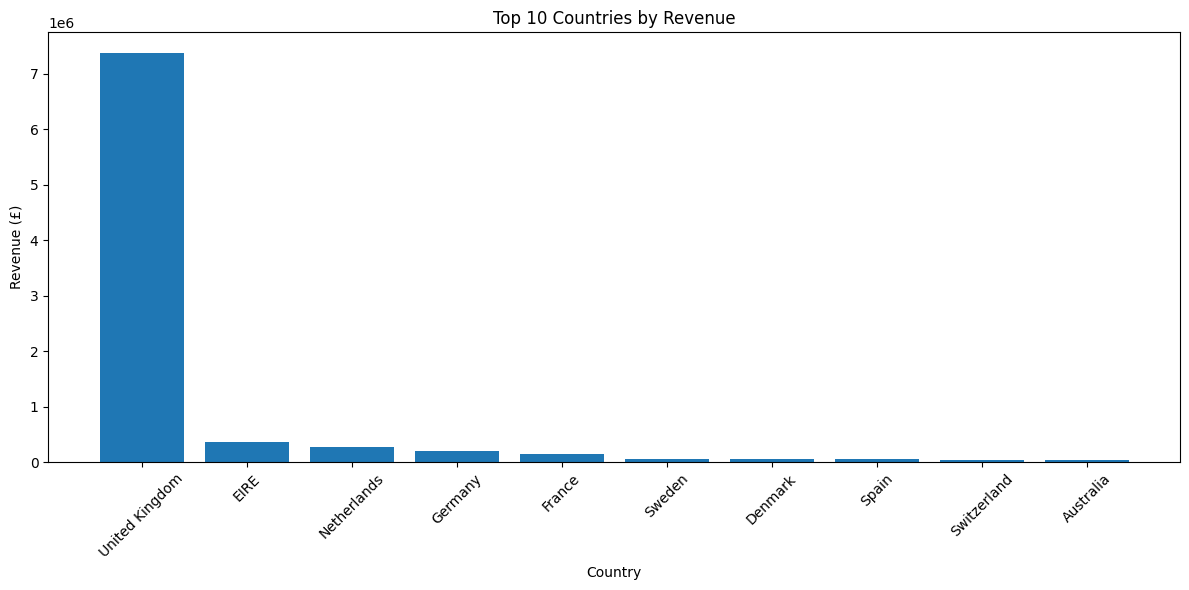

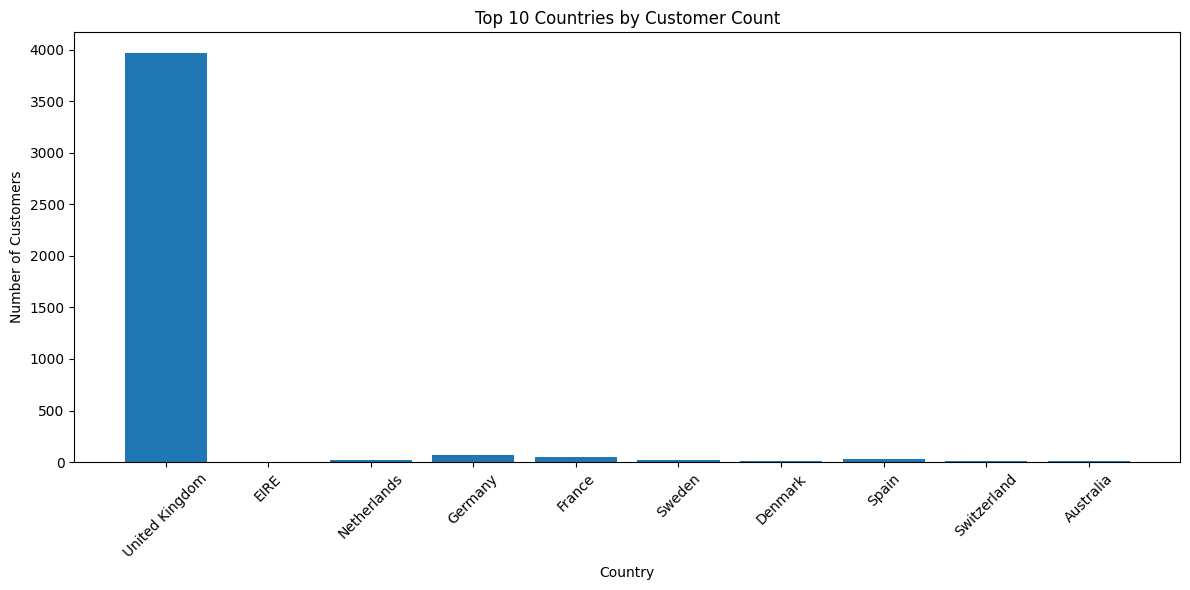


BUSINESS HIGHLIGHTS
Highest Revenue Country: United Kingdom
Total Countries: 37
Top Country Revenue: £ 7381644.43


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_excel('/content/online_retail_II.xlsx')


df = df.drop_duplicates()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["IsCancelled"] = df["Invoice"].astype(str).str.startswith("C")

df = df[~df["IsCancelled"]].copy()
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)].copy()
df = df.dropna(subset=["Customer ID", "Country"]).copy()

df["Revenue"] = df["Quantity"] * df["Price"]

country_analysis = df.groupby("Country").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Orders=("Invoice", "nunique"),
    Total_Customers=("Customer ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
)


country_analysis["Average_Order_Value"] = (
    country_analysis["Total_Revenue"] /
    country_analysis["Total_Orders"]
)


country_analysis = country_analysis.sort_values(
    by="Total_Revenue", ascending=False
)


print("COUNTRY-WISE BUSINESS PERFORMANCE")
display(country_analysis.round(2))


top_countries = country_analysis.head(10)

print("\nTOP 10 REVENUE-GENERATING COUNTRIES")
display(top_countries.round(2))


top_countries["Revenue_Percentage"] = (
    top_countries["Total_Revenue"] /
    country_analysis["Total_Revenue"].sum()
) * 100

plt.figure(figsize=(12, 6))
plt.bar(top_countries.index, top_countries["Total_Revenue"])
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


plt.figure(figsize=(12, 6))
plt.bar(top_countries.index, top_countries["Total_Customers"])
plt.title("Top 10 Countries by Customer Count")
plt.xlabel("Country")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
fw
print("\nBUSINESS HIGHLIGHTS")
print("Highest Revenue Country:", country_analysis.index[0])
print("Total Countries:", len(country_analysis))
print(
    "Top Country Revenue: £",
    round(country_analysis["Total_Revenue"].iloc[0], 2)
)

TOP 10 PRODUCTS BY REVENUE


,StockCode,Description,Total_Revenue,Total_Quantity,Total_Orders
4074,85123A,WHITE HANGING HEART T-LIGHT HOLDER,151339.16,56814,3021
1708,22423,REGENCY CAKESTAND 3 TIER,143727.60,12484,1687
4466,M,Manual,98531.99,2568,382
2864,84879,ASSORTED COLOUR BIRD ORNAMENT,70291.03,44431,1333
4063,85099B,JUMBO BAG RED RETROSPOT,51644.25,29519,1060
4468,POST,POSTAGE,48741.08,2212,738
2710,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,40156.05,21579,244
1310,22086,PAPER CHAIN KIT 50'S CHRISTMAS,36871.55,13839,796
2529,47566,PARTY BUNTING,35017.30,8312,710
3126,15056N,EDWARDIAN PARASOL NATURAL,34044.75,7201,496


TOP 10 PRODUCTS BY QUANTITY SOLD


,StockCode,Description,Total_Revenue,Total_Quantity,Total_Orders
4074,85123A,WHITE HANGING HEART T-LIGHT HOLDER,151339.16,56814,3021
2694,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,11285.54,54610,461
51,17003,BROCADE RING PURSE,8847.66,48166,188
526,21212,PACK OF 72 RETRO SPOT CAKE CASES,21838.23,45129,1160
2864,84879,ASSORTED COLOUR BIRD ORNAMENT,70291.03,44431,1333
2910,84991,60 TEATIME FAIRY CAKE CASES,17436.30,35656,1136
1218,21977,PACK OF 60 PINK PAISLEY CAKE CASES,15045.10,30871,928
4063,85099B,JUMBO BAG RED RETROSPOT,51644.25,29519,1060
1435,22197,SMALL POPCORN HOLDER,19518.21,25703,678
2467,37410,BLACK AND WHITE PAISLEY FLOWER MUG,3019.57,25685,18


10 LOWEST REVENUE PRODUCTS (MINIMUM 5 ORDERS)


,StockCode,Description,Total_Revenue,Total_Quantity,Total_Orders
4467,PADS,PADS TO MATCH ALL CUSHIONS,0.014,14,14
3583,79149B,SILICON STAR BULB BLUE,5.040,12,5
3074,90111,BLUE HIBISCUS HAIR CLIP,7.350,7,6
3470,62074B,ELEPHANT CLIP W SUCTION CUP,7.560,18,7
3258,35597D,PINK/WHITE CHRISTMAS TREE 30CM,7.800,12,5
3120,10124G,ARMY CAMO BOOKCOVER TAPE,8.400,20,6
2597,72708,SCULPTED ROUND IVORY CANDLE,9.240,44,5
4455,90214V,"LETTER ""V"" BLING KEY RING",10.000,8,7
3360,44089A,PINK GAUZE BUTTERFLY LAMPSHADE,10.080,24,8
1,10080,GROOVY CACTUS INFLATABLE,10.200,12,5



BUSINESS HIGHLIGHTS
Top Revenue Product: WHITE HANGING HEART T-LIGHT HOLDER
Top Selling Product: WHITE HANGING HEART T-LIGHT HOLDER
Top 10 Revenue Contribution: 8.07 %


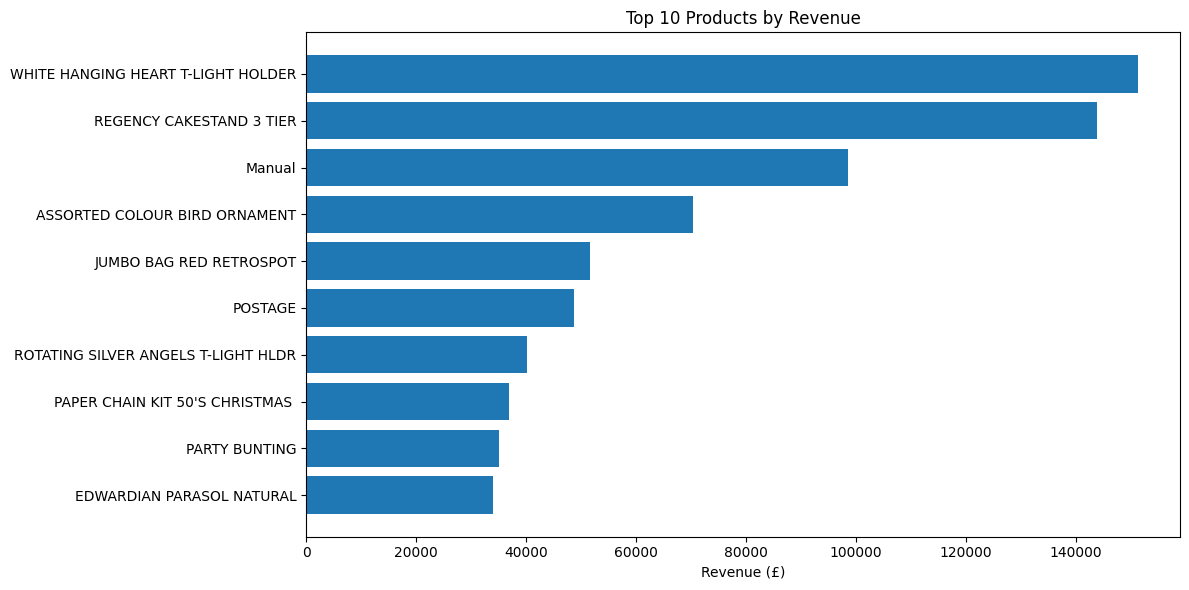

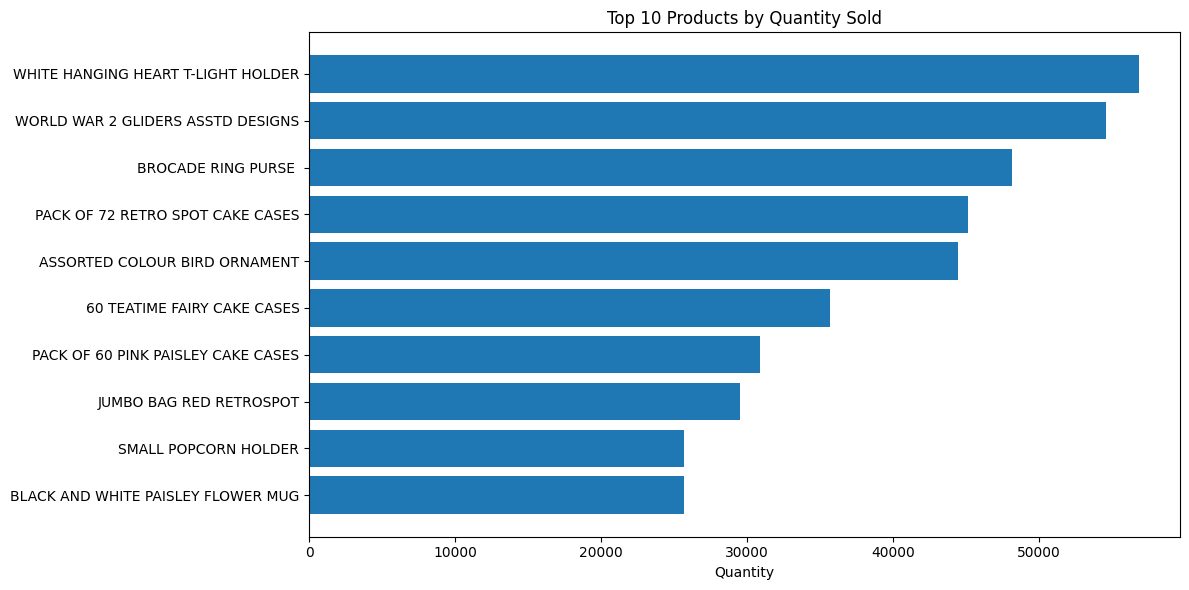

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_excel('/content/online_retail_II.xlsx')


df = df.drop_duplicates()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["IsCancelled"] = df["Invoice"].astype(str).str.startswith("C")

df = df[~df["IsCancelled"]].copy()
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)].copy()
df = df.dropna(subset=["Customer ID", "Description"]).copy()

df["Revenue"] = df["Quantity"] * df["Price"]


product_analysis = df.groupby(
    ["StockCode", "Description"]
).agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Invoice", "nunique")
).reset_index()


top_revenue = product_analysis.sort_values(
    "Total_Revenue", ascending=False
).head(10)


top_quantity = product_analysis.sort_values(
    "Total_Quantity", ascending=False
).head(10)


lowest_products = product_analysis[
    product_analysis["Total_Orders"] >= 5
].sort_values("Total_Revenue").head(10)


print("TOP 10 PRODUCTS BY REVENUE")
display(top_revenue)

print("TOP 10 PRODUCTS BY QUANTITY SOLD")
display(top_quantity)

print("10 LOWEST REVENUE PRODUCTS (MINIMUM 5 ORDERS)")
display(lowest_products)


total_revenue = product_analysis["Total_Revenue"].sum()
top_10_revenue = top_revenue["Total_Revenue"].sum()

print("\nBUSINESS HIGHLIGHTS")
print("Top Revenue Product:", top_revenue.iloc[0]["Description"])
print("Top Selling Product:", top_quantity.iloc[0]["Description"])
print("Top 10 Revenue Contribution:",
      round((top_10_revenue / total_revenue) * 100, 2), "%")


plt.figure(figsize=(12, 6))
plt.barh(top_revenue["Description"], top_revenue["Total_Revenue"])
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
plt.barh(top_quantity["Description"], top_quantity["Total_Quantity"])
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

CUSTOMER ANALYSIS


,Total_Revenue,Total_Orders,Total_Quantity,Last_Purchase,First_Purchase,Average_Order_Value,Purchase_Duration_Days
Customer ID,,,,,,,
18102.0,349164.35,89,124216,2010-12-09 13:44:00,2009-12-01 09:24:00,3923.19,373
14646.0,248396.50,78,170278,2010-11-30 16:28:00,2009-12-02 16:52:00,3184.57,362
14156.0,196549.74,102,108105,2010-12-03 11:48:00,2009-12-01 12:30:00,1926.96,366
14911.0,152121.22,205,69709,2010-12-09 12:17:00,2009-12-01 11:41:00,742.05,373
13694.0,131443.19,94,125893,2010-12-01 12:12:00,2009-12-04 15:26:00,1398.33,361
17511.0,84541.17,31,55107,2010-12-07 09:51:00,2009-12-02 10:52:00,2727.13,369
15061.0,83284.38,86,51791,2010-12-07 13:50:00,2009-12-01 12:18:00,968.42,371
16684.0,80489.21,27,54555,2010-11-25 11:04:00,2009-12-07 12:56:00,2981.08,352
16754.0,65500.07,29,63551,2010-12-02 17:38:00,2010-03-08 11:32:00,2258.62,269



TOP 10 CUSTOMERS BY REVENUE


,Total_Revenue,Total_Orders,Total_Quantity,Last_Purchase,First_Purchase,Average_Order_Value,Purchase_Duration_Days
Customer ID,,,,,,,
18102.0,349164.35,89,124216,2010-12-09 13:44:00,2009-12-01 09:24:00,3923.19,373
14646.0,248396.50,78,170278,2010-11-30 16:28:00,2009-12-02 16:52:00,3184.57,362
14156.0,196549.74,102,108105,2010-12-03 11:48:00,2009-12-01 12:30:00,1926.96,366
14911.0,152121.22,205,69709,2010-12-09 12:17:00,2009-12-01 11:41:00,742.05,373
13694.0,131443.19,94,125893,2010-12-01 12:12:00,2009-12-04 15:26:00,1398.33,361
17511.0,84541.17,31,55107,2010-12-07 09:51:00,2009-12-02 10:52:00,2727.13,369
15061.0,83284.38,86,51791,2010-12-07 13:50:00,2009-12-01 12:18:00,968.42,371
16684.0,80489.21,27,54555,2010-11-25 11:04:00,2009-12-07 12:56:00,2981.08,352
16754.0,65500.07,29,63551,2010-12-02 17:38:00,2010-03-08 11:32:00,2258.62,269



BUSINESS HIGHLIGHTS
Total Customers: 4312
Highest Spending Customer: 18102.0
Highest Customer Revenue: £ 349164.35
Average Customer Revenue: £ 2040.41


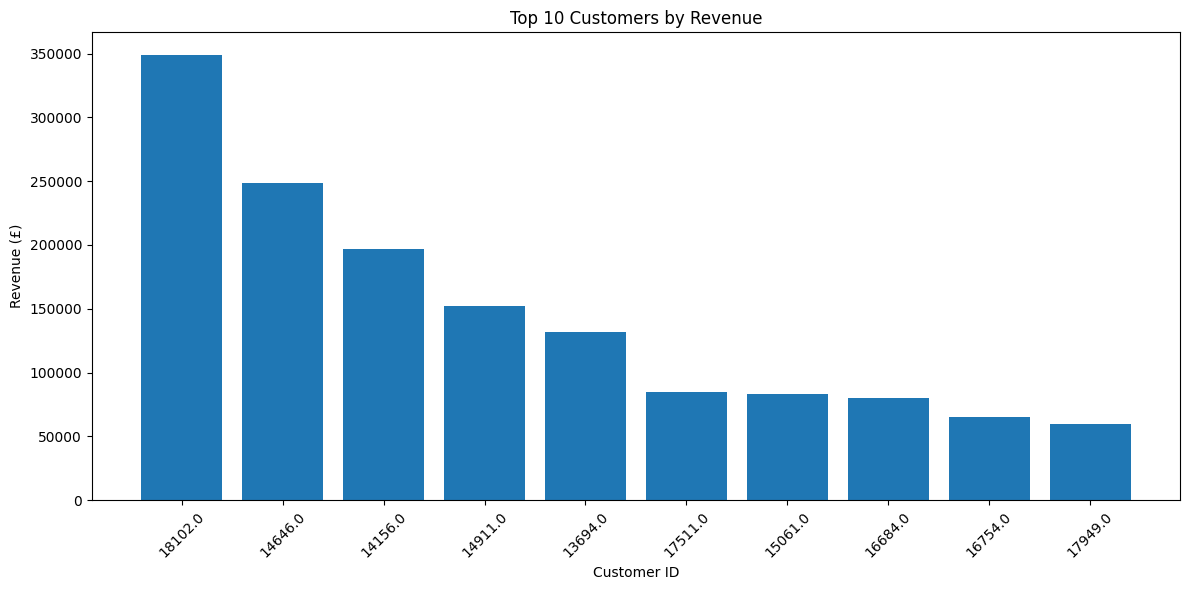

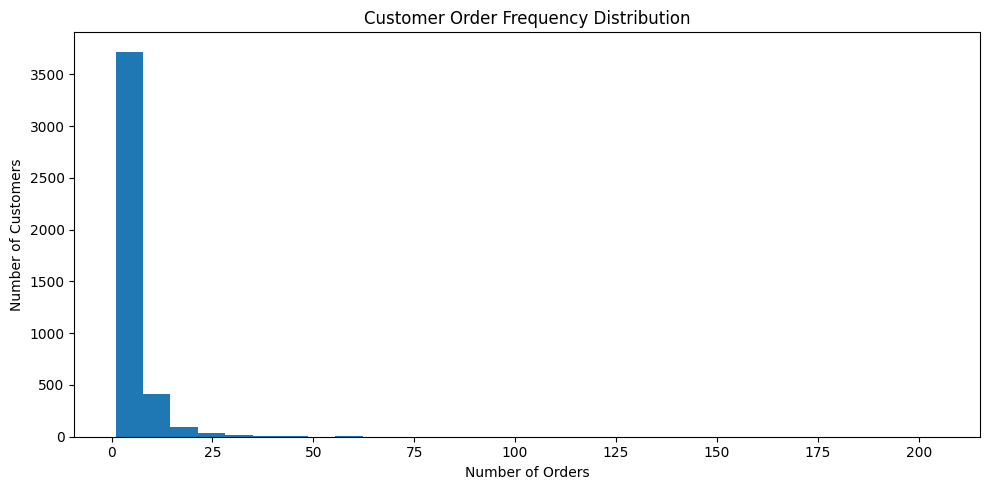

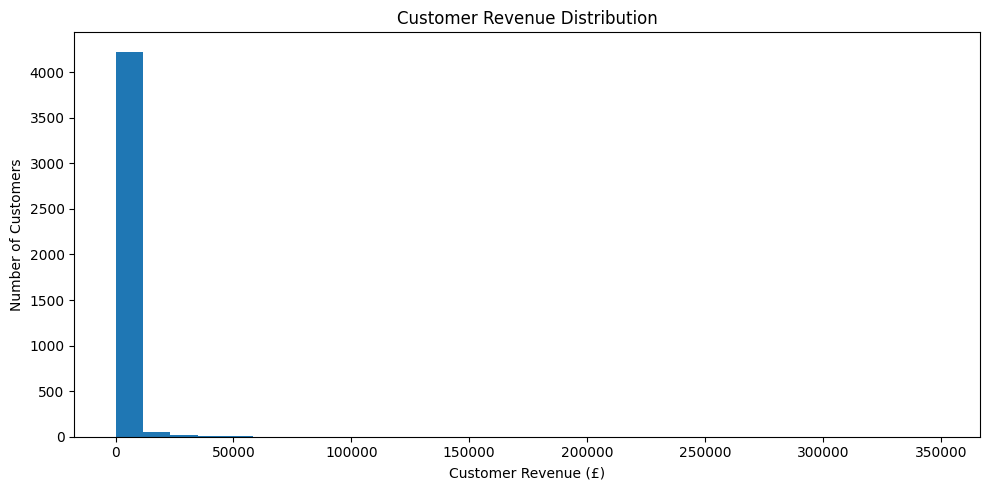

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_excel('/content/online_retail_II.xlsx')


df = df.drop_duplicates()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["IsCancelled"] = df["Invoice"].astype(str).str.startswith("C")

df = df[~df["IsCancelled"]].copy()
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)].copy()
df = df.dropna(subset=["Customer ID"]).copy()


df["Revenue"] = df["Quantity"] * df["Price"]


customer_analysis = df.groupby("Customer ID").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Orders=("Invoice", "nunique"),
    Total_Quantity=("Quantity", "sum"),
    Last_Purchase=("InvoiceDate", "max"),
    First_Purchase=("InvoiceDate", "min")
)


customer_analysis["Average_Order_Value"] = (
    customer_analysis["Total_Revenue"] /
    customer_analysis["Total_Orders"]
)


customer_analysis["Purchase_Duration_Days"] = (
    customer_analysis["Last_Purchase"] -
    customer_analysis["First_Purchase"]
).dt.days


customer_analysis = customer_analysis.sort_values(
    "Total_Revenue", ascending=False
)


print("CUSTOMER ANALYSIS")
display(customer_analysis.head(10).round(2))

print("\nTOP 10 CUSTOMERS BY REVENUE")
display(customer_analysis.head(10).round(2))


print("\nBUSINESS HIGHLIGHTS")
print("Total Customers:", len(customer_analysis))
print("Highest Spending Customer:",
      customer_analysis["Total_Revenue"].idxmax())
print("Highest Customer Revenue: £",
      round(customer_analysis["Total_Revenue"].max(), 2))
print("Average Customer Revenue: £",
      round(customer_analysis["Total_Revenue"].mean(), 2))

top_customers = customer_analysis.head(10)

plt.figure(figsize=(12, 6))
plt.bar(
    top_customers.index.astype(str),
    top_customers["Total_Revenue"]
)
plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 5))
plt.hist(customer_analysis["Total_Orders"], bins=30)
plt.title("Customer Order Frequency Distribution")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(customer_analysis["Total_Revenue"], bins=30)
plt.title("Customer Revenue Distribution")
plt.xlabel("Customer Revenue (£)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

RFM CUSTOMER ANALYSIS


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
Customer ID,,,,,,,
12346.0,165,11,372.86,2,5,2,252
12347.0,3,2,1323.32,5,2,4,524
12348.0,74,1,222.16,2,1,1,211
12349.0,43,3,2671.14,3,3,5,335
12351.0,11,1,300.93,5,1,2,512
12352.0,11,2,343.80,5,2,2,522
12353.0,44,1,317.76,3,1,2,312
12355.0,203,1,488.21,1,1,2,112
12356.0,16,3,3560.30,4,3,5,435



RFM SUMMARY


,Recency,Frequency,Monetary
count,4312.00,4312.00,4312.00
mean,91.17,4.46,2040.41
std,96.86,8.17,8911.76
min,1.00,1.00,2.95
25%,18.00,1.00,307.19
50%,53.00,2.00,701.62
75%,136.00,5.00,1714.93
max,374.00,205.00,349164.35



TOP 10 CUSTOMERS BY MONETARY VALUE


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
Customer ID,,,,,,,
18102.0,1,89,349164.35,5,5,5,555
14646.0,10,78,248396.50,5,5,5,555
14156.0,7,102,196549.74,5,5,5,555
14911.0,1,205,152121.22,5,5,5,555
13694.0,9,94,131443.19,5,5,5,555
17511.0,3,31,84541.17,5,5,5,555
15061.0,3,86,83284.38,5,5,5,555
16684.0,15,27,80489.21,4,5,5,455
16754.0,8,29,65500.07,5,5,5,555


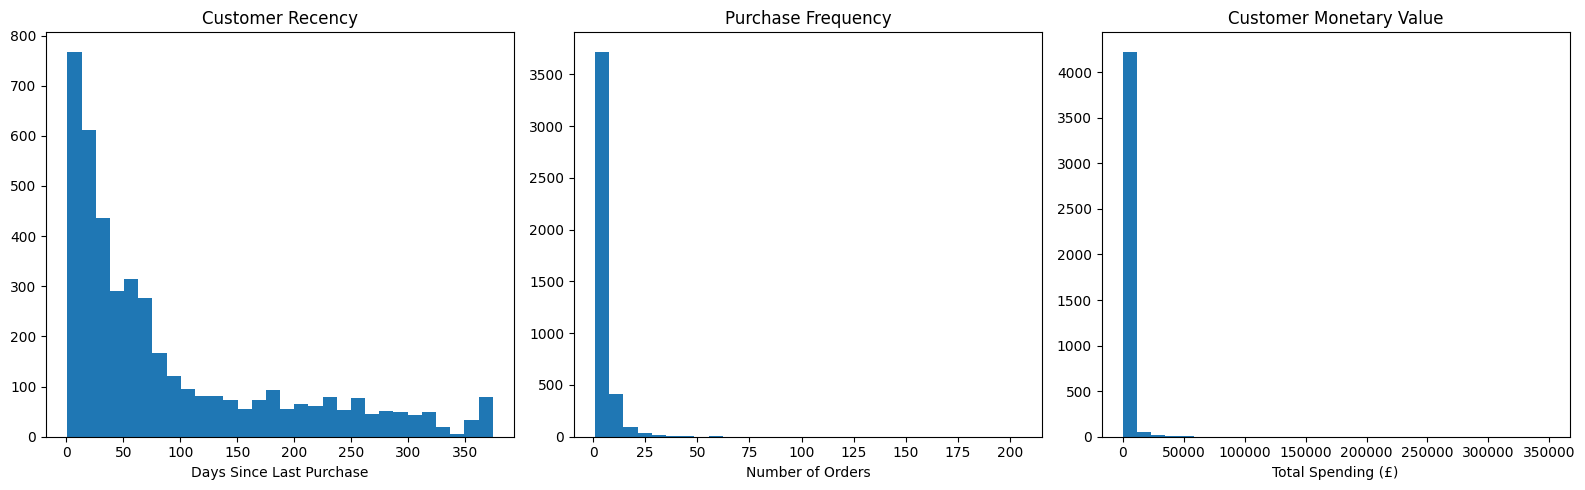


Total Customers Analysed: 4312


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df = pd.read_excel('/content/online_retail_II.xlsx')


df = df.drop_duplicates()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["IsCancelled"] = df["Invoice"].astype(str).str.startswith("C")

df = df[~df["IsCancelled"]].copy()
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)].copy()
df = df.dropna(subset=["Customer ID"]).copy()

df["Revenue"] = df["Quantity"] * df["Price"]


reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)


rfm = df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum")
)


rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5, labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)


rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)


print("RFM CUSTOMER ANALYSIS")
display(rfm.head(15))


print("\nRFM SUMMARY")
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))


print("\nTOP 10 CUSTOMERS BY MONETARY VALUE")
display(rfm.nlargest(10, "Monetary"))


fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].hist(rfm["Recency"], bins=30)
axes[0].set_title("Customer Recency")
axes[0].set_xlabel("Days Since Last Purchase")

axes[1].hist(rfm["Frequency"], bins=30)
axes[1].set_title("Purchase Frequency")
axes[1].set_xlabel("Number of Orders")

axes[2].hist(rfm["Monetary"], bins=30)
axes[2].set_title("Customer Monetary Value")
axes[2].set_xlabel("Total Spending (£)")

plt.tight_layout()
plt.show()

print("\nTotal Customers Analysed:", len(rfm))

CUSTOMER SEGMENTATION SUMMARY


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Segment
Cluster,,,,,
0,945,23.95,1.97,532.08,Occasional
1,778,13.83,13.56,7381.58,High-Value
2,1378,190.57,1.30,305.66,At-Risk
3,1211,80.21,4.14,1759.99,Loyal



CUSTOMER-LEVEL SEGMENTATION


,Recency,Frequency,Monetary,Cluster,Segment
Customer ID,,,,,
12346.0,165,11,372.86,3,Loyal
12347.0,3,2,1323.32,0,Occasional
12348.0,74,1,222.16,2,At-Risk
12349.0,43,3,2671.14,3,Loyal
12351.0,11,1,300.93,0,Occasional
12352.0,11,2,343.80,0,Occasional
12353.0,44,1,317.76,0,Occasional
12355.0,203,1,488.21,2,At-Risk
12356.0,16,3,3560.30,3,Loyal



CUSTOMER COUNT BY SEGMENT


,count
Segment,
At-Risk,1378
Loyal,1211
Occasional,945
High-Value,778



Silhouette Score: 0.331


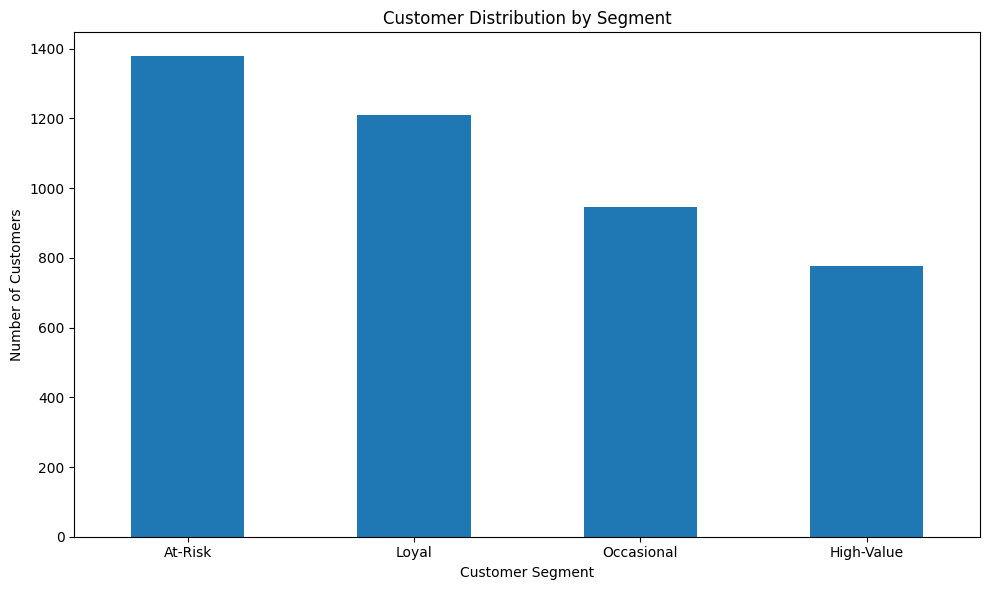

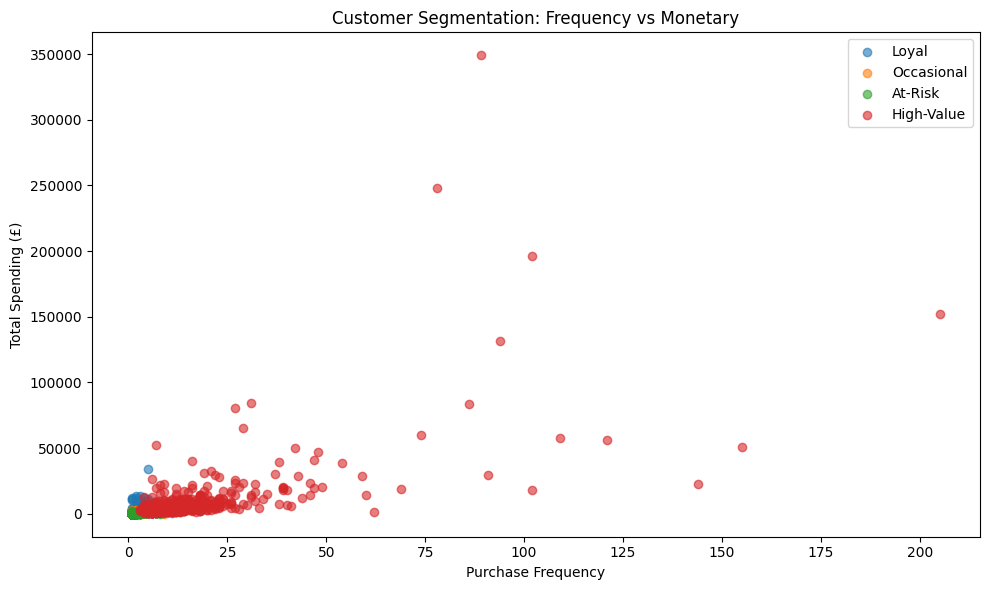

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_excel('/content/online_retail_II.xlsx')


df = df.drop_duplicates()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["IsCancelled"] = df["Invoice"].astype(str).str.startswith("C")

df = df[~df["IsCancelled"]].copy()
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)].copy()
df = df.dropna(subset=["Customer ID"]).copy()

df["Revenue"] = df["Quantity"] * df["Price"]


reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum")
)


features = ["Recency", "Frequency", "Monetary"]

X = rfm[features].copy()


X = np.log1p(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm["Cluster"] = kmeans.fit_predict(X_scaled)

cluster_summary = rfm.groupby("Cluster").agg(
    Customers=("Recency", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

cluster_summary["Segment"] = "Occasional"

high_value = (
    cluster_summary["Avg_Frequency"].rank(pct=True)
    + cluster_summary["Avg_Monetary"].rank(pct=True)
    + (1 - cluster_summary["Avg_Recency"].rank(pct=True))
)

cluster_summary.loc[high_value.idxmax(), "Segment"] = "High-Value"

remaining = cluster_summary[
    cluster_summary["Segment"] == "Occasional"
]

if not remaining.empty:
    at_risk = remaining["Avg_Recency"].idxmax()
    cluster_summary.loc[at_risk, "Segment"] = "At-Risk"

remaining = cluster_summary[
    cluster_summary["Segment"] == "Occasional"
]

if not remaining.empty:
    loyal = remaining["Avg_Frequency"].idxmax()
    cluster_summary.loc[loyal, "Segment"] = "Loyal"

segment_map = cluster_summary["Segment"].to_dict()
rfm["Segment"] = rfm["Cluster"].map(segment_map)


print("CUSTOMER SEGMENTATION SUMMARY")
display(cluster_summary)

print("\nCUSTOMER-LEVEL SEGMENTATION")
display(rfm.head(15))

print("\nCUSTOMER COUNT BY SEGMENT")
display(rfm["Segment"].value_counts())


print("\nSilhouette Score:",
      round(silhouette_score(X_scaled, rfm["Cluster"]), 3))


plt.figure(figsize=(10, 6))
rfm["Segment"].value_counts().plot(kind="bar")
plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 6))
for segment in rfm["Segment"].unique():
    subset = rfm[rfm["Segment"] == segment]
    plt.scatter(
        subset["Frequency"],
        subset["Monetary"],
        label=segment,
        alpha=0.6
    )

plt.title("Customer Segmentation: Frequency vs Monetary")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Spending (£)")
plt.legend()
plt.tight_layout()
plt.show()

       BUSINESS INSIGHTS & RECOMMENDATIONS

1. OVERALL BUSINESS PERFORMANCE
Total Revenue: £8,798,233.74
Total Orders: 19,213
Total Customers: 4,312
Average Order Value: £457.93

2. REVENUE TREND
Best Revenue Month: 2010-11
Revenue: £1,166,460.02
Lowest Revenue Month: 2010-12
Revenue: £310,656.37

3. COUNTRY PERFORMANCE
Top Country: United Kingdom
Revenue: £7,381,644.43

4. PRODUCT PERFORMANCE
Top Revenue Product: WHITE HANGING HEART T-LIGHT HOLDER
Revenue: £151,339.16

5. CUSTOMER SEGMENTATION


,Number of Customers
Segment,
Occasional,2090
At-Risk,1087
High-Value,710
Loyal,425



6. BUSINESS RECOMMENDATIONS
- High-Value Customers:
  Introduce loyalty rewards and exclusive offers.
- Loyal Customers:
  Encourage repeat purchases through membership benefits.
- At-Risk Customers:
  Use personalized campaigns to encourage customers to return.
- Occasional Customers:
  Use product recommendations and targeted promotions.
- Country Expansion:
  Study the success factors of United Kingdom before expanding into similar markets.
- Product Strategy:
  Monitor demand and inventory for WHITE HANGING HEART T-LIGHT HOLDER.
- Revenue Growth:
  Study seasonal revenue patterns to plan marketing campaigns.


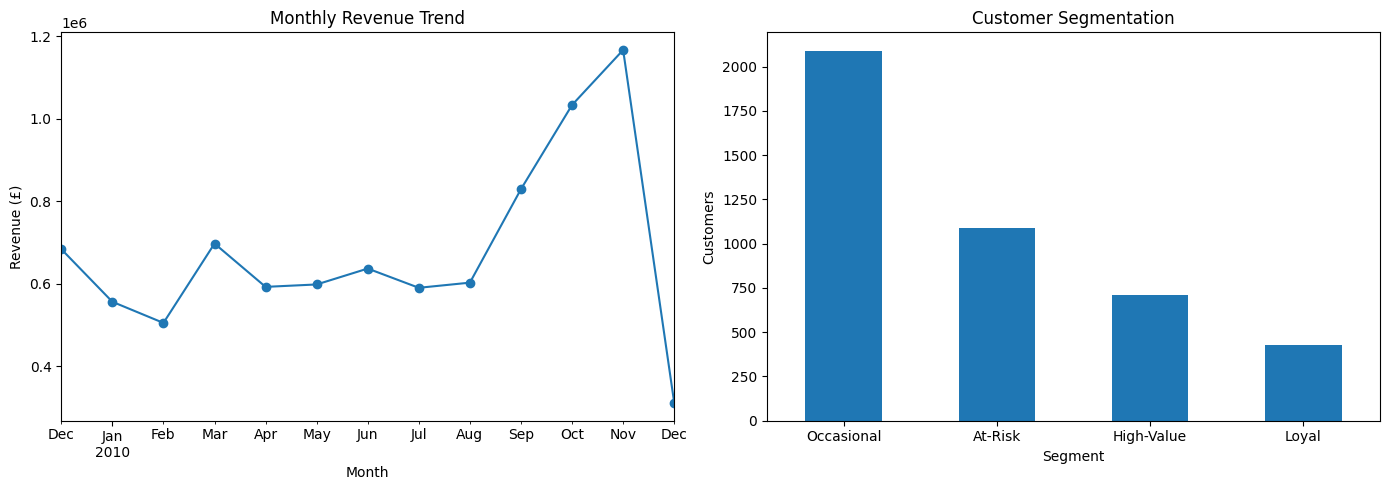

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load and preprocess dataset
df = pd.read_excel('/content/online_retail_II.xlsx')

df = df.drop_duplicates()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["IsCancelled"] = df["Invoice"].astype(str).str.startswith("C")

df = df[~df["IsCancelled"]].copy()
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)].copy()
df = df.dropna(subset=["Customer ID", "Description", "Country"]).copy()

# 2. Calculate revenue
df["Revenue"] = df["Quantity"] * df["Price"]

# 3. Overall KPIs
total_revenue = df["Revenue"].sum()
total_orders = df["Invoice"].nunique()
total_customers = df["Customer ID"].nunique()
average_order_value = total_revenue / total_orders

# 4. Monthly revenue analysis
df["MonthYear"] = df["InvoiceDate"].dt.to_period("M")
monthly_revenue = df.groupby("MonthYear")["Revenue"].sum()

best_month = monthly_revenue.idxmax()
worst_month = monthly_revenue.idxmin()

# 5. Country analysis
country_revenue = df.groupby("Country")["Revenue"].sum().sort_values(
    ascending=False
)

top_country = country_revenue.index[0]
top_country_revenue = country_revenue.iloc[0]

# 6. Product analysis
product_revenue = df.groupby("Description")["Revenue"].sum().sort_values(
    ascending=False
)

top_product = product_revenue.index[0]

# 7. Customer RFM analysis
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum")
)

# 8. Customer segmentation
rfm["Segment"] = "Occasional"

high_value = (
    (rfm["Frequency"] >= rfm["Frequency"].quantile(0.75)) &
    (rfm["Monetary"] >= rfm["Monetary"].quantile(0.75)) &
    (rfm["Recency"] <= rfm["Recency"].quantile(0.50))
)

rfm.loc[high_value, "Segment"] = "High-Value"

at_risk = (
    (rfm["Recency"] >= rfm["Recency"].quantile(0.75)) &
    (~high_value)
)

rfm.loc[at_risk, "Segment"] = "At-Risk"

loyal = (
    (rfm["Frequency"] >= rfm["Frequency"].quantile(0.75)) &
    (~high_value) & (~at_risk)
)

rfm.loc[loyal, "Segment"] = "Loyal"

segment_counts = rfm["Segment"].value_counts()

# 9. Generate business insights
print("=" * 55)
print("       BUSINESS INSIGHTS & RECOMMENDATIONS")
print("=" * 55)

print("\n1. OVERALL BUSINESS PERFORMANCE")
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")

print("\n2. REVENUE TREND")
print(f"Best Revenue Month: {best_month}")
print(f"Revenue: £{monthly_revenue.max():,.2f}")
print(f"Lowest Revenue Month: {worst_month}")
print(f"Revenue: £{monthly_revenue.min():,.2f}")

print("\n3. COUNTRY PERFORMANCE")
print(f"Top Country: {top_country}")
print(f"Revenue: £{top_country_revenue:,.2f}")

print("\n4. PRODUCT PERFORMANCE")
print(f"Top Revenue Product: {top_product}")
print(f"Revenue: £{product_revenue.iloc[0]:,.2f}")

print("\n5. CUSTOMER SEGMENTATION")
display(segment_counts.to_frame("Number of Customers"))

print("\n6. BUSINESS RECOMMENDATIONS")

print("- High-Value Customers:")
print("  Introduce loyalty rewards and exclusive offers.")

print("- Loyal Customers:")
print("  Encourage repeat purchases through membership benefits.")

print("- At-Risk Customers:")
print("  Use personalized campaigns to encourage customers to return.")

print("- Occasional Customers:")
print("  Use product recommendations and targeted promotions.")

print("- Country Expansion:")
print(f"  Study the success factors of {top_country} before expanding into similar markets.")

print("- Product Strategy:")
print(f"  Monitor demand and inventory for {top_product}.")

print("- Revenue Growth:")
print("  Study seasonal revenue patterns to plan marketing campaigns.")

# 10. Business insights visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

monthly_revenue.plot(ax=axes[0], marker="o")
axes[0].set_title("Monthly Revenue Trend")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue (£)")

segment_counts.plot(kind="bar", ax=axes[1])
axes[1].set_title("Customer Segmentation")
axes[1].set_xlabel("Segment")
axes[1].set_ylabel("Customers")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
# Export cleaned dataset
df.to_csv("Online_Retail_Cleaned.csv", index=False)

# Download CSV file
from google.colab import files
files.download("Online_Retail_Cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

import pandas as pd
import numpy as np


df = pd.read_excel('/content/online_retail_II.xlsx')


df = df.drop_duplicates()

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df = df[
    ~df["Invoice"].astype(str).str.startswith("C")
].copy()

df = df[
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

df = df.dropna(subset=["Customer ID"]).copy()


df["Revenue"] = df["Quantity"] * df["Price"]

start_date = df["InvoiceDate"].min()

observation_end = start_date + pd.DateOffset(years=1)

prediction_end = observation_end + pd.Timedelta(days=90)

historical = df[
    df["InvoiceDate"] < observation_end
].copy()

future = df[
    (df["InvoiceDate"] >= observation_end) &
    (df["InvoiceDate"] < prediction_end)
].copy()


print("Observation Start:", start_date)
print("Observation End:", observation_end)
print("Prediction End:", prediction_end)

print("\nHistorical Transactions:", len(historical))
print("Future Transactions:", len(future))

print("\nHistorical Customers:",
      historical["Customer ID"].nunique())

print("Future Customers:",
      future["Customer ID"].nunique())


Observation Start: 2009-12-01 07:45:00
Observation End: 2010-12-01 07:45:00
Prediction End: 2011-03-01 07:45:00

Historical Transactions: 386732
Future Transactions: 14184

Historical Customers: 4266
Future Customers: 573


In [4]:

# Create customer features from historical transactions

customer_features = historical.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x:
             (observation_end - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
    Average_Order_Value=("Revenue", "sum")
).copy()

# Calculate average order value
customer_features["Average_Order_Value"] = (
    customer_features["Average_Order_Value"] /
    customer_features["Frequency"]
)


future_customers = future["Customer ID"].unique()

customer_features["Target"] = (
    customer_features.index.isin(future_customers)
).astype(int)


print("CUSTOMER FEATURE DATASET")
display(customer_features.head(10))

print("\nTARGET DISTRIBUTION")
print(customer_features["Target"].value_counts())

print("\nTARGET PERCENTAGES")
print(
    customer_features["Target"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nDataset Shape:", customer_features.shape)


CUSTOMER FEATURE DATASET


,Recency,Frequency,Monetary,Average_Order_Value,Target
Customer ID,,,,,
12346.0,155,11,372.86,33.896364,0
12347.0,30,1,611.53,611.530000,1
12348.0,64,1,222.16,222.160000,0
12349.0,33,3,2671.14,890.380000,0
12351.0,1,1,300.93,300.930000,0
12352.0,1,2,343.80,171.900000,0
12353.0,34,1,317.76,317.760000,0
12355.0,193,1,488.21,488.210000,0
12356.0,6,3,3560.30,1186.766667,0



TARGET DISTRIBUTION
Target
0    3739
1     527
Name: count, dtype: int64

TARGET PERCENTAGES
Target
0    87.65
1    12.35
Name: proportion, dtype: float64

Dataset Shape: (4266, 5)


In [5]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Define features and target
X = customer_features[
    ["Recency", "Frequency", "Monetary", "Average_Order_Value"]
]

y = customer_features["Target"]

# Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Predictions
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Evaluation
print("RANDOM FOREST MODEL RESULTS")
print("--------------------------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred, zero_division=0))


RANDOM FOREST MODEL RESULTS
--------------------------------
Accuracy: 0.8326
Precision: 0.3538
Recall: 0.4381
F1 Score: 0.3915
ROC-AUC: 0.7676

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.92      0.89      0.90       749
           1       0.35      0.44      0.39       105

    accuracy                           0.83       854
   macro avg       0.64      0.66      0.65       854
weighted avg       0.85      0.83      0.84       854



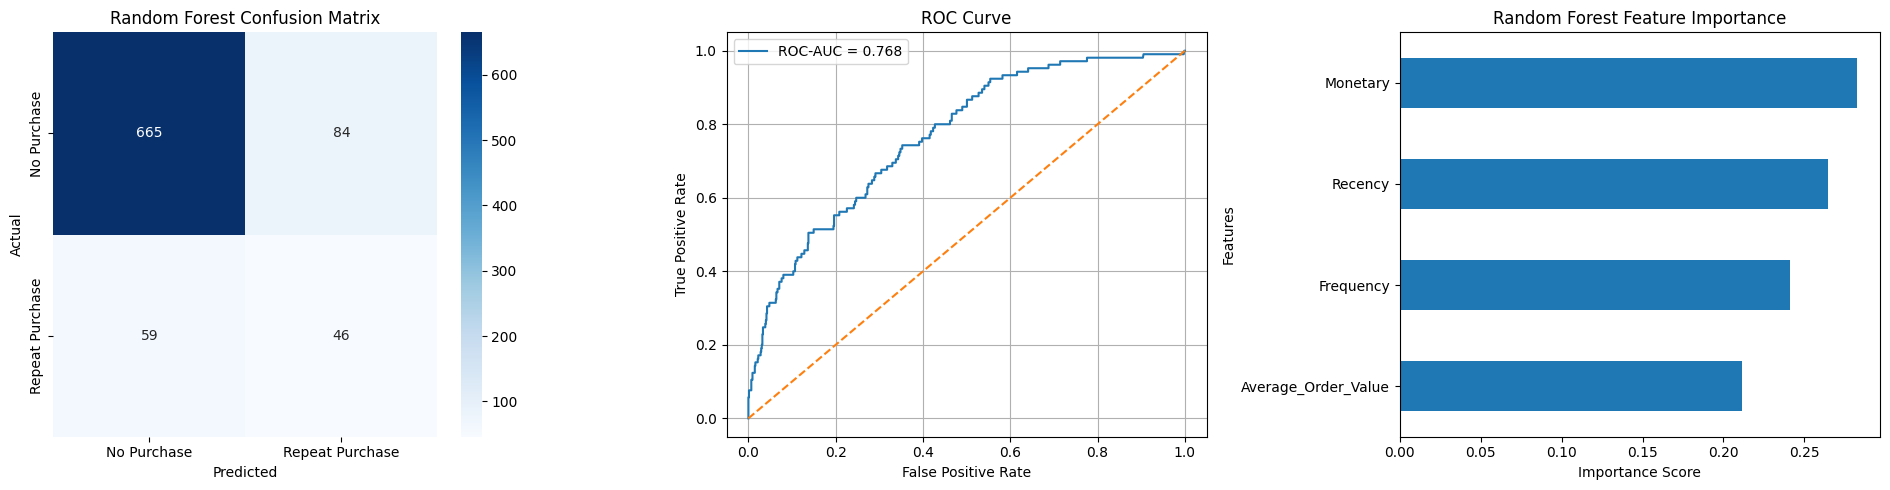

FEATURE IMPORTANCE


,Importance
Monetary,0.282664
Recency,0.264362
Frequency,0.241364
Average_Order_Value,0.211611


In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

# Create visualization layout
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Purchase", "Repeat Purchase"],
    yticklabels=["No Purchase", "Repeat Purchase"],
    ax=axes[0]
)

axes[0].set_title("Random Forest Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# 2. ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

axes[1].plot(
    fpr, tpr,
    label=f"ROC-AUC = {auc(fpr, tpr):.3f}"
)

axes[1].plot([0, 1], [0, 1], linestyle="--")
axes[1].set_title("ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()
axes[1].grid(True)

# 3. Feature Importance
importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values()

importance.plot(
    kind="barh",
    ax=axes[2]
)

axes[2].set_title("Random Forest Feature Importance")
axes[2].set_xlabel("Importance Score")
axes[2].set_ylabel("Features")

plt.tight_layout()
plt.show()

# Display feature importance values
print("FEATURE IMPORTANCE")
display(importance.sort_values(ascending=False).to_frame("Importance"))


In [7]:

# Export cleaned dataset for Power BI

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df["Year"] = df["InvoiceDate"].dt.year
df["Month"] = df["InvoiceDate"].dt.month
df["Quarter"] = "Q" + df["InvoiceDate"].dt.quarter.astype(str)
df["MonthYear"] = df["InvoiceDate"].dt.strftime("%Y-%m")

df.to_csv("Retail_Cleaned_Data.csv", index=False)

from google.colab import files
files.download("Retail_Cleaned_Data.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from google.colab import files

# Prepare customer data
customer_segments = customer_features.copy()

# Features used for clustering (exclude Target)
features = ["Recency", "Frequency", "Monetary", "Average_Order_Value"]

# Log transformation
X_rfm = np.log1p(customer_segments[features])

# Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_rfm)

# K-Means clustering
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

customer_segments["Cluster"] = kmeans.fit_predict(X_scaled)

# Export Customer ID as a column
customer_segments = customer_segments.reset_index()

# Save and download
customer_segments.to_csv("Customer_Segments_Final.csv", index=False)

print("Customer Segmentation Summary:")
print(customer_segments["Cluster"].value_counts().sort_index())

print("\nFinal Dataset Shape:", customer_segments.shape)
print(customer_segments.head())

files.download("Customer_Segments_Final.csv")


Customer Segmentation Summary:
Cluster
0    1179
1     975
2    1253
3     859
Name: count, dtype: int64

Final Dataset Shape: (4266, 7)
   Customer ID  Recency  Frequency  Monetary  Average_Order_Value  Target  \
0      12346.0      155         11    372.86            33.896364       0   
1      12347.0       30          1    611.53           611.530000       1   
2      12348.0       64          1    222.16           222.160000       0   
3      12349.0       33          3   2671.14           890.380000       0   
4      12351.0        1          1    300.93           300.930000       0   

   Cluster  
0        0  
1        2  
2        0  
3        2  
4        1  


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import pandas as pd
from google.colab import files

# Create Random Forest prediction results
rf_results = X_test.copy()

rf_results["Actual"] = y_test
rf_results["Predicted"] = y_pred
rf_results["Probability"] = y_prob

rf_results = rf_results.reset_index()

# Export
rf_results.to_csv("Random_Forest_Predictions.csv", index=False)

# Export feature importance
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance_df.to_csv("RF_Feature_Importance.csv", index=False)

# Download both files
files.download("Random_Forest_Predictions.csv")
files.download("RF_Feature_Importance.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)
from google.colab import files

metrics = pd.DataFrame({
    "Metric": [
        "Accuracy", "Precision", "Recall",
        "F1 Score", "ROC-AUC"
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ]
})

metrics.to_csv("RF_Model_Metrics.csv", index=False)
files.download("RF_Model_Metrics.csv")

print(metrics)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

      Metric     Score
0   Accuracy  0.832553
1  Precision  0.353846
2     Recall  0.438095
3   F1 Score  0.391489
4    ROC-AUC  0.767550


In [13]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Check whether customer_features is available
if "customer_features" not in globals():
    print("customer_features is missing. Tell me, and we'll reload it.")
else:
    features = [
        "Recency",
        "Frequency",
        "Monetary",
        "Average_Order_Value"
    ]

    # Prepare and scale RFM features
    X_rfm = np.log1p(customer_features[features])
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_rfm)

    # Apply K-Means clustering
    kmeans = KMeans(
        n_clusters=4,
        random_state=42,
        n_init=10
    )

    clusters = kmeans.fit_predict(X_scaled)

    # Calculate Silhouette Score
    score = silhouette_score(X_scaled, clusters)

    # Create cluster summary
    results = customer_features.copy()
    results["Cluster"] = clusters

    summary = results.groupby("Cluster").agg(
        Customer_Count=("Cluster", "count"),
        Average_Recency=("Recency", "mean"),
        Average_Frequency=("Frequency", "mean"),
        Average_Monetary=("Monetary", "mean"),
        Average_Order_Value=("Average_Order_Value", "mean"),
        Total_Revenue=("Monetary", "sum")
    ).round(2)

    print("SILHOUETTE SCORE:", round(score, 4))
    print("\nCLUSTER SUMMARY:")
    display(summary)


SILHOUETTE SCORE: 0.2699

CLUSTER SUMMARY:


,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary,Average_Order_Value,Total_Revenue
Cluster,,,,,,
0,1179,170.89,1.46,223.90,166.15,263973.06
1,975,18.82,2.86,651.15,247.46,634867.66
2,1253,108.21,2.57,1379.95,602.69,1729078.90
3,859,19.43,12.45,6821.49,497.56,5859657.75


In [14]:

print("PROJECT BUSINESS KPIs")
print("-" * 35)

total_revenue = df["Revenue"].sum()
total_orders = df["Invoice"].nunique()
total_customers = df["Customer ID"].nunique()
total_products = df["StockCode"].nunique()
average_order_value = total_revenue / total_orders

print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Products: {total_products:,}")
print(f"Average Order Value: {average_order_value:,.2f}")

print("\nDATASET PERIOD")
print("-" * 35)
print("Start Date:", df["InvoiceDate"].min())
print("End Date:", df["InvoiceDate"].max())
print("Years:", sorted(df["Year"].unique()))


PROJECT BUSINESS KPIs
-----------------------------------
Total Revenue: 8,798,233.74
Total Orders: 19,213
Total Customers: 4,312
Total Products: 4,017
Average Order Value: 457.93

DATASET PERIOD
-----------------------------------
Start Date: 2009-12-01 07:45:00
End Date: 2010-12-09 20:01:00
Years: [np.int32(2009), np.int32(2010)]
